# 💰 QuickLoan: The Great Model Bake-Off
### Ensemble learning for loan-default risk · MAIB in-class challenge

> **One expert can be wrong. A committee of experts wins.** This notebook runs that committee and scores every model in **dirhams as well as accuracy**.

**The business problem.** QuickLoan, a UAE fintech, approves or rejects small personal loans. Its two possible mistakes have very different costs:

| | Model **approves** (predict 0) | Model **rejects** (predict 1) |
|---|---|---|
| **Actually repays** | +20 % of the loan (interest earned) | 0 (interest lost) |
| **Actually defaults** | −100 % of the loan 💸 | 0 (disaster avoided ✅) |

Approving a borrower who then defaults costs **five times** as much as rejecting a good one (100 % of the loan vs 20 %). So every model is scored on the **same test set** with three numbers: **Accuracy · Recall on defaulters · Money saved** (compared with approving everyone).

| Step | What happens |
|---|---|
| **1** | Load, explore, encode, split (no leakage) |
| **2** | Weak single models: Decision Tree, Logistic Regression, KNN |
| **3** | The four ensembles: Voting · Bagging · Boosting (incl. XGBoost) · Stacking |
| **4** | The leaderboard (accuracy vs recall vs money), then the threshold twist and a robustness check |
| **5** | Verdict for QuickLoan leadership, plus `loan_model.joblib` for the dashboard |

<sub>The numbers in the commentary come from this saved run. Other library versions may shift them slightly.</sub>

## 0 · Setup
Libraries, plus one vibrant palette that stays fixed in every chart, one colour per model **family**:
🔵 sky = single model · 🟣 violet = voting · 🟢 emerald = bagging · 🩷 pink = boosting · 🟠 amber = stacking.
The palette was checked for colour-blind separation, and every bar also carries a text label.

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────
import warnings, time
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import joblib
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from IPython.display import display

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RepeatedStratifiedKFold, cross_val_predict)
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (VotingClassifier, BaggingClassifier, RandomForestClassifier,
                              AdaBoostClassifier, GradientBoostingClassifier, StackingClassifier)
from sklearn.metrics import accuracy_score, recall_score, precision_score, log_loss

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:          # the brief allows HistGradientBoosting as a stand-in
    from sklearn.ensemble import HistGradientBoostingClassifier
    HAS_XGB = False

RS = 42                      # one seed for every model → the bake-off is reproducible
print("XGBoost available:", HAS_XGB)

XGBoost available: True


In [2]:
# ── Vibrant, colour-blind-checked palette: one colour per model FAMILY ─────
FAMILY_COLORS = {
    "Single":   "#38BDF8",   # sky      – lone experts
    "Voting":   "#7C3AED",   # violet   – show of hands
    "Bagging":  "#059669",   # emerald  – many copies, averaged
    "Boosting": "#F472B6",   # pink     – a relay team fixing mistakes
    "Stacking": "#F59E0B",   # amber    – the committee with a manager
}
GOOD, WARN, BAD, INK, MUTED = "#0ca30c", "#ec835a", "#d03b3b", "#1d1b2e", "#8a87a0"

pio.templates["quickloan"] = go.layout.Template(layout=dict(
    font=dict(family="Inter, Segoe UI, Helvetica, Arial, sans-serif", size=13, color=INK),
    title=dict(font=dict(size=18), x=0.01, xanchor="left"),
    paper_bgcolor="white", plot_bgcolor="white",
    colorway=list(FAMILY_COLORS.values()),
    xaxis=dict(gridcolor="#ecebf3", linecolor="#d6d4e0", zerolinecolor="#d6d4e0"),
    yaxis=dict(gridcolor="#ecebf3", linecolor="#d6d4e0", zerolinecolor="#d6d4e0"),
    hoverlabel=dict(font_size=13, bgcolor="white"),
    margin=dict(l=70, r=40, t=80, b=60),
))
pio.templates.default = "plotly_white+quickloan"

def aed(x):
    """Format a number as AED with thousands separators."""
    return ("−" if x < 0 else "") + f"AED {abs(x):,.0f}"

## Step 1 · Load & explore

In [3]:
df = pd.read_csv("loans.csv")
print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   Missing values: {df.isna().sum().sum()}")
display(df.head())
display(df.describe().T[["mean", "min", "50%", "max"]].round(2))

Rows: 6,000   Columns: 11   Missing values: 0


,age,annual_income,loan_amount,loan_term_months,employment_years,credit_history_months,num_existing_loans,past_defaults,debt_to_income,home_ownership,default
0,24,133500.0,46300.0,24,4.4,170,0,0,0.35,rent,0
1,55,33400.0,40600.0,24,1.6,100,1,0,1.22,mortgage,0
2,49,152100.0,45800.0,36,14.1,253,1,0,0.30,rent,0
3,40,67400.0,32800.0,36,1.4,294,0,0,0.49,rent,0
4,40,143900.0,68900.0,24,14.5,289,1,1,0.48,rent,0


,mean,min,50%,max
age,42.45,21.00,42.00,64.0
annual_income,96184.63,30400.00,90200.00,361400.0
loan_amount,50536.57,6700.00,45800.00,210700.0
loan_term_months,33.65,12.00,36.00,60.0
employment_years,5.98,0.00,5.00,35.0
credit_history_months,149.28,0.00,150.00,299.0
num_existing_loans,1.10,0.00,1.00,6.0
past_defaults,0.24,0.00,0.00,4.0
debt_to_income,0.60,0.03,0.51,3.0
default,0.13,0.00,0.00,1.0


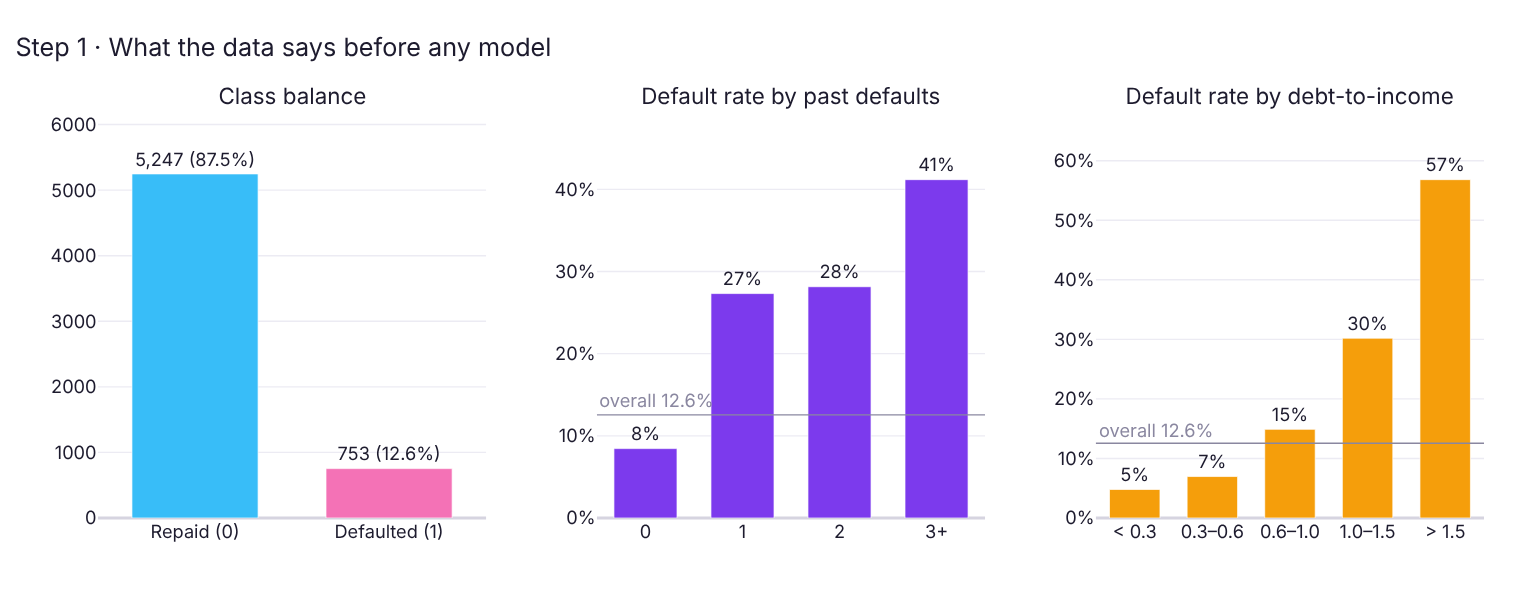

In [4]:
overall = df["default"].mean()
fig = make_subplots(rows=1, cols=3, horizontal_spacing=0.08, subplot_titles=(
    "Class balance", "Default rate by past defaults", "Default rate by debt-to-income"))

counts = df["default"].value_counts().sort_index()
fig.add_bar(x=["Repaid (0)", "Defaulted (1)"], y=counts.values, marker_color=["#38BDF8", "#F472B6"],
            text=[f"{v:,} ({v/len(df):.1%})" for v in counts.values], textposition="outside",
            hovertemplate="%{x}: %{y:,} applicants<extra></extra>", row=1, col=1)

past = df["past_defaults"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"})
g1 = df.groupby(past)["default"].agg(["mean", "size"]).reindex(["0", "1", "2", "3+"])
fig.add_bar(x=g1.index, y=g1["mean"], marker_color="#7C3AED", customdata=g1["size"],
            text=[f"{v:.0%}" for v in g1["mean"]], textposition="outside",
            hovertemplate="Past defaults = %{x}: %{y:.1%} default (n=%{customdata:,})<extra></extra>", row=1, col=2)

bands = pd.cut(df["debt_to_income"], [-np.inf, .3, .6, 1.0, 1.5, np.inf],
               labels=["< 0.3", "0.3–0.6", "0.6–1.0", "1.0–1.5", "> 1.5"])
g2 = df.groupby(bands, observed=True)["default"].agg(["mean", "size"])
fig.add_bar(x=g2.index.astype(str), y=g2["mean"], marker_color="#F59E0B", customdata=g2["size"],
            text=[f"{v:.0%}" for v in g2["mean"]], textposition="outside",
            hovertemplate="DTI %{x}: %{y:.1%} default (n=%{customdata:,})<extra></extra>", row=1, col=3)

for c in (2, 3):
    fig.add_hline(y=overall, line_color=MUTED, line_width=1, row=1, col=c,
                  annotation_text=f"overall {overall:.1%}", annotation_position="top left",
                  annotation_font_color=MUTED)
    fig.update_yaxes(tickformat=".0%", rangemode="tozero", row=1, col=c)
fig.update_yaxes(range=[0, counts.max() * 1.18], row=1, col=1)
fig.update_yaxes(range=[0, g1["mean"].max() * 1.2], row=1, col=2)
fig.update_yaxes(range=[0, g2["mean"].max() * 1.2], row=1, col=3)
fig.update_layout(height=430, showlegend=False, bargap=0.35,
                  title="Step 1 · What the data says before any model")
fig.show()

**What the data says**
- **About 1 in 8 applicants default** (753 of 6,000, 12.6 %), so the classes are imbalanced. A "model" that simply approves everyone is about **87.5 % accurate** and saves **AED 0**. That is the accuracy trap in one line.
- **Past defaults** more than triple the risk: 8 % with none, 27 % with one, 41 % with three or more.
- **Debt-to-income (DTI)** is the strongest single signal. The default rate climbs from 5 % (DTI < 0.3) to **57 %** (DTI > 1.5).

### Encode & split
- **One-hot encode** `home_ownership` (rent / own / mortgage becomes three 0/1 columns).
- **Stratified 75 / 25 split** with `random_state=1`. This is the same split as the provided `app.py`, so the dashboard reproduces our numbers exactly.
- `loan_test` is kept aside for the money metric.
- **Leakage guard-rails:** scaling lives *inside* pipelines (fitted on training rows only), decision cut-offs are tuned on training folds only, and the test set is used only to score.

In [5]:
# One-hot encode the single categorical column. get_dummies works row by row
# (nothing is learned from the data), so encoding before the split cannot leak.
X = pd.get_dummies(df.drop(columns="default"), columns=["home_ownership"], dtype=int)
y = df["default"]

# Same split as the provided app.py (25 % test, stratified, random_state=1),
# so the dashboard's money card scores exactly this test set.
X_train, X_test, y_train, y_test, loan_train, loan_test = train_test_split(
    X, y, df["loan_amount"], test_size=0.25, random_state=1, stratify=y)

print("Features:", list(X.columns))
print(f"Train: {len(X_train):,} rows ({y_train.mean():.1%} defaulters)")
print(f"Test : {len(X_test):,} rows ({y_test.mean():.1%} defaulters)  <- used ONLY for final scoring")
print(f"Test loan book: {aed(loan_test.sum())}, of which defaulters' loans: {aed(loan_test[y_test == 1].sum())}")

Features: ['age', 'annual_income', 'loan_amount', 'loan_term_months', 'employment_years', 'credit_history_months', 'num_existing_loans', 'past_defaults', 'debt_to_income', 'home_ownership_mortgage', 'home_ownership_own', 'home_ownership_rent']
Train: 4,500 rows (12.6% defaulters)
Test : 1,500 rows (12.5% defaulters)  <- used ONLY for final scoring
Test loan book: AED 75,216,900, of which defaulters' loans: AED 12,271,900


### The money metric
This is the exact function from the brief. Three reference points frame every result that follows:

In [6]:
def money_saved(y_true, y_pred, loan_amounts, interest=0.20):
    import numpy as np
    y_true = np.array(y_true); y_pred = np.array(y_pred); loan = np.array(loan_amounts)
    caught_defaulter = (y_pred==1) & (y_true==1)   # correctly rejected a defaulter -> loan SAVED
    wrongly_rejected = (y_pred==1) & (y_true==0)   # rejected a good borrower   -> interest LOST
    return loan[caught_defaulter].sum()  -  interest * loan[wrongly_rejected].sum()

# Three reference points on the test set
n_test = len(y_test)
approve_all = money_saved(y_test, np.zeros(n_test), loan_test)
reject_all  = money_saved(y_test, np.ones(n_test), loan_test)
perfect     = money_saved(y_test, y_test, loan_test)
print(f"Approve everyone    : {aed(approve_all):>16}   (accuracy {1 - y_test.mean():.1%}, the accuracy trap)")
print(f"Reject everyone     : {aed(reject_all):>16}")
print(f"Perfect crystal ball: {aed(perfect):>16}   <- the most any model could save")

Approve everyone    :            AED 0   (accuracy 87.5%, the accuracy trap)
Reject everyone     :     −AED 317,100
Perfect crystal ball:   AED 12,271,900   <- the most any model could save


Every model lands somewhere between **−AED 0.3 M** (reject everyone) and **AED 12.3 M** (perfect). The gap between a model's score and AED 12.3 M is money still lost to defaulters it failed to catch.

The helpers below fit each model on the training set, score it on the test set and add a row to the leaderboard. Every model goes through the same function, which keeps the comparison fair.

In [7]:
board, fitted, FAMILY = [], {}, {}      # leaderboard rows, trained models, model -> family

def evaluate(name, family, model, threshold=None):
    """Score a TRAINED model on the shared test set.
    threshold=None -> the model's own .predict() (the default 50 % rule);
    a number       -> reject when P(default) >= threshold."""
    if threshold is None:
        pred = model.predict(X_test)
    else:
        pred = (model.predict_proba(X_test)[:, 1] >= threshold).astype(int)
    yt, lt = y_test.values, loan_test.values
    return {
        "Model": name, "Family": family,
        "Accuracy": accuracy_score(yt, pred),
        "Recall": recall_score(yt, pred),
        "Precision": precision_score(yt, pred, zero_division=0),
        "Money saved (AED)": money_saved(yt, pred, lt),
        "Caught": int(((pred == 1) & (yt == 1)).sum()),
        "Good rejected": int(((pred == 1) & (yt == 0)).sum()),
        "Missed": int(((pred == 0) & (yt == 1)).sum()),
        "Threshold": 0.5 if threshold is None else threshold,
    }

def add(name, family, model):
    """Fit on the training set, score on the test set, add a leaderboard row."""
    t0 = time.time()
    model.fit(X_train, y_train)
    fitted[name], FAMILY[name] = model, family
    row = evaluate(name, family, model)
    row["Fit time (s)"] = round(time.time() - t0, 2)
    board.append(row)
    return row

def show_table(rows, extra=()):
    cols = ["Model", "Family", "Accuracy", "Recall", "Money saved (AED)",
            "Caught", "Good rejected", "Missed", *extra]
    return (pd.DataFrame(rows)[cols].style
            .format({"Accuracy": "{:.1%}", "Recall": "{:.1%}", "Money saved (AED)": "{:,.0f}",
                     "Threshold": "{:.2f}"})
            .hide(axis="index"))

def caught_missed_chart(rows, title):
    names = [r["Model"] for r in rows]
    fig = go.Figure()
    fig.add_bar(y=names, x=[r["Caught"] for r in rows], orientation="h", marker_color=GOOD,
                name="✅ Defaulter caught → loan saved", text=[f"{r['Caught']} caught" for r in rows],
                textposition="inside", insidetextanchor="start", textfont_color="white")
    fig.add_bar(y=names, x=[r["Missed"] for r in rows], orientation="h", marker_color=BAD,
                name="💸 Defaulter missed → loan lost", text=[f"{r['Missed']} missed" for r in rows],
                textposition="inside", insidetextanchor="end", textfont_color="white")
    fig.update_layout(barmode="stack", bargap=0.4, height=120 + 55 * len(rows), title=title,
                      xaxis_title=f"The {int(y_test.sum())} defaulters hiding in the test set",
                      legend=dict(orientation="h", y=1.02, yanchor="bottom", x=1, xanchor="right", traceorder="normal"))
    fig.update_yaxes(autorange="reversed")
    fig.show()

## Step 2 · Feel the pain: weak single models
Three lone experts, each with its own way of thinking:
- 🌳 **Shallow Decision Tree (depth 3)**: a loan officer who may ask only three yes/no questions.
- 📋 **Logistic Regression**: a points scorecard where each fact adds or subtracts risk points.
- 👥 **KNN (k = 15)**: finds the 15 most similar past applicants and copies what happened to them.

In [8]:
singles = {
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=RS),                   # asks only 3 yes/no questions
    "Logistic Reg.": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),     # a points scorecard
    "KNN":           make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),  # copies 15 look-alikes
}
for name, model in singles.items():
    add(name, "Single", model)
show_table(board)

Model,Family,Accuracy,Recall,Money saved (AED),Caught,Good rejected,Missed
Decision Tree,Single,89.5%,27.7%,"3,926,160",52,22,136
Logistic Reg.,Single,88.8%,21.8%,"3,307,300",41,21,147
KNN,Single,88.1%,12.2%,"1,972,840",23,13,165


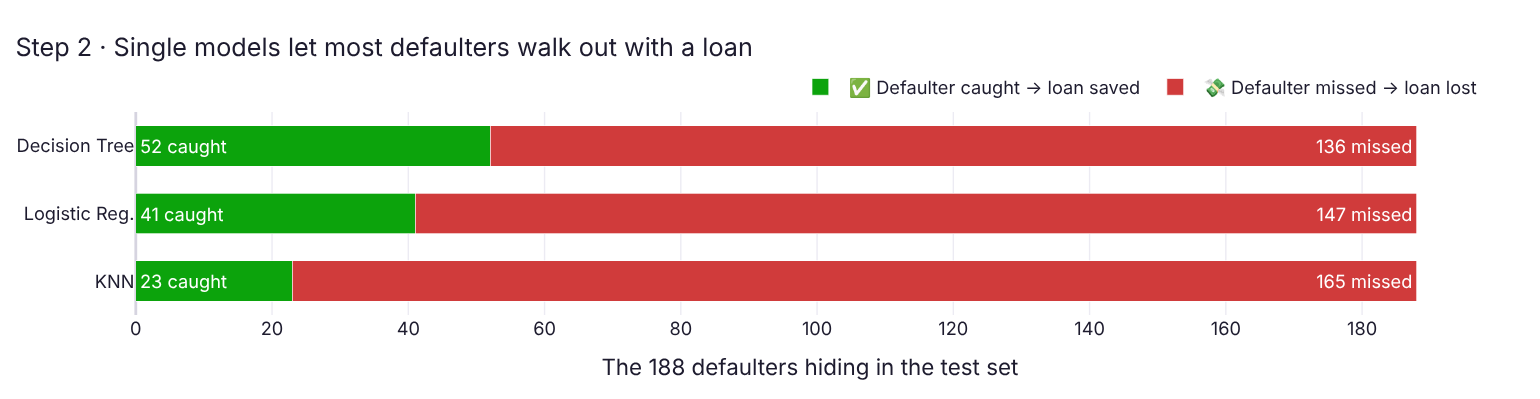

In [9]:
caught_missed_chart(board[:3], "Step 2 · Single models let most defaulters walk out with a loan")

**The pain, in numbers.** All three score **88–89 % accuracy**, barely above the 87.5 % you get by approving everyone, yet they catch only **12–28 % of defaulters**. KNN lets **165 of 188** defaulters walk out with a loan. The best single model (the tree) saves AED 3.93 M, and KNN saves about half of that.

Accuracy hides the problem. When 87.5 % of borrowers repay, a model can look clever while saying "approve" almost every time.

## Step 3 · Build the four ensembles
Four ways to run a committee of experts:

| Ensemble | Committee analogy | What it fights |
|---|---|---|
| 🗳️ **Voting** | Ask several *different* experts, then take the majority (hard) or average their confidence (soft) | Individual blind spots |
| 🎒 **Bagging** | Clone one expert 200 times, give each clone a different random slice of the data, average them | **Variance**: unstable, over-fitted models |
| 🏃 **Boosting** | A relay team: each new expert studies the cases the previous ones got wrong | **Bias**: models too simple to see the pattern |
| 🧑‍💼 **Stacking** | Strong experts give their opinions and a *manager* model learns how much to trust each one | Combines strengths across families |

### 3.1 · Voting
Hard voting counts yes/no votes. Soft voting averages probabilities, so a very confident expert counts for more.

In [10]:
trio = [("tree", singles["Decision Tree"]), ("logreg", singles["Logistic Reg."]), ("knn", singles["KNN"])]
add("Voting (hard)", "Voting", VotingClassifier(trio, voting="hard"))   # majority of 3 yes/no votes
add("Voting (soft)", "Voting", VotingClassifier(trio, voting="soft"))   # average of 3 probabilities
show_table(board[-2:])

Model,Family,Accuracy,Recall,Money saved (AED),Caught,Good rejected,Missed
Voting (hard),Voting,88.5%,15.4%,"2,395,820",29,14,159
Voting (soft),Voting,88.9%,20.7%,"3,210,960",39,17,149


**Voting didn't help here.** Both versions finish *below* the lone decision tree. The committee is three weak experts, and KNN pulls the average towards "approve". A committee is only as good as its members' independent insight, which is why the stacking model below uses strong members.

### 3.2 · Bagging (and Random Forest)

In [11]:
# Why bag? One fully-grown tree memorises its training data (high variance)...
deep = DecisionTreeClassifier(random_state=RS).fit(X_train, y_train)
print(f"One deep tree -> train accuracy {deep.score(X_train, y_train):.1%}, "
      f"test accuracy {deep.score(X_test, y_test):.1%}, "
      f"money saved {aed(money_saved(y_test, deep.predict(X_test), loan_test))}")

# ...bagging grows 200 such trees, each on a different bootstrap sample, and averages them.
add("Bagging", "Bagging", BaggingClassifier(DecisionTreeClassifier(random_state=RS),
                                            n_estimators=200, random_state=RS, n_jobs=-1))
# Random Forest = bagging + every split may only look at a random subset of features.
add("Random Forest", "Bagging", RandomForestClassifier(n_estimators=400, random_state=RS, n_jobs=-1))
show_table(board[-2:])

One deep tree -> train accuracy 100.0%, test accuracy 82.7%, money saved AED 4,155,980


Model,Family,Accuracy,Recall,Money saved (AED),Caught,Good rejected,Missed
Bagging,Bagging,89.1%,31.4%,"4,466,960",59,35,129
Random Forest,Bagging,89.4%,30.3%,"4,420,000",57,28,131


**Bagging tames the over-fitter.** One fully grown tree scores 100 % on training data but only 82.7 % on test, because it memorised the noise. Averaging 200 bootstrapped trees lifts test accuracy to 89.1 % and money from AED 4.16 M to **AED 4.47 M**. Random Forest also randomises which features each split may use, and lands at AED 4.42 M. Both beat every single model.

### 3.3 · Boosting: AdaBoost, Gradient Boosting, XGBoost
AdaBoost re-weights the applicants it misclassified. Gradient Boosting and XGBoost fit each new small tree to the errors that remain, and XGBoost adds regularisation and speed.

In [12]:
def make_xgb():
    if HAS_XGB:
        return XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                             colsample_bytree=0.8, eval_metric="logloss", random_state=RS, n_jobs=4)
    return HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, random_state=RS)

XGB_NAME = "XGBoost" if HAS_XGB else "HistGB (XGB stand-in)"
add("AdaBoost", "Boosting", AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=RS))
add("Gradient Boosting", "Boosting", GradientBoostingClassifier(n_estimators=200, learning_rate=0.05,
                                                                max_depth=3, random_state=RS))
add(XGB_NAME, "Boosting", make_xgb())
show_table(board[-3:])

Model,Family,Accuracy,Recall,Money saved (AED),Caught,Good rejected,Missed
AdaBoost,Boosting,88.9%,18.6%,"2,814,220",35,14,153
Gradient Boosting,Boosting,89.6%,33.5%,"4,768,240",63,31,125
XGBoost,Boosting,89.3%,31.4%,"4,580,800",59,31,129


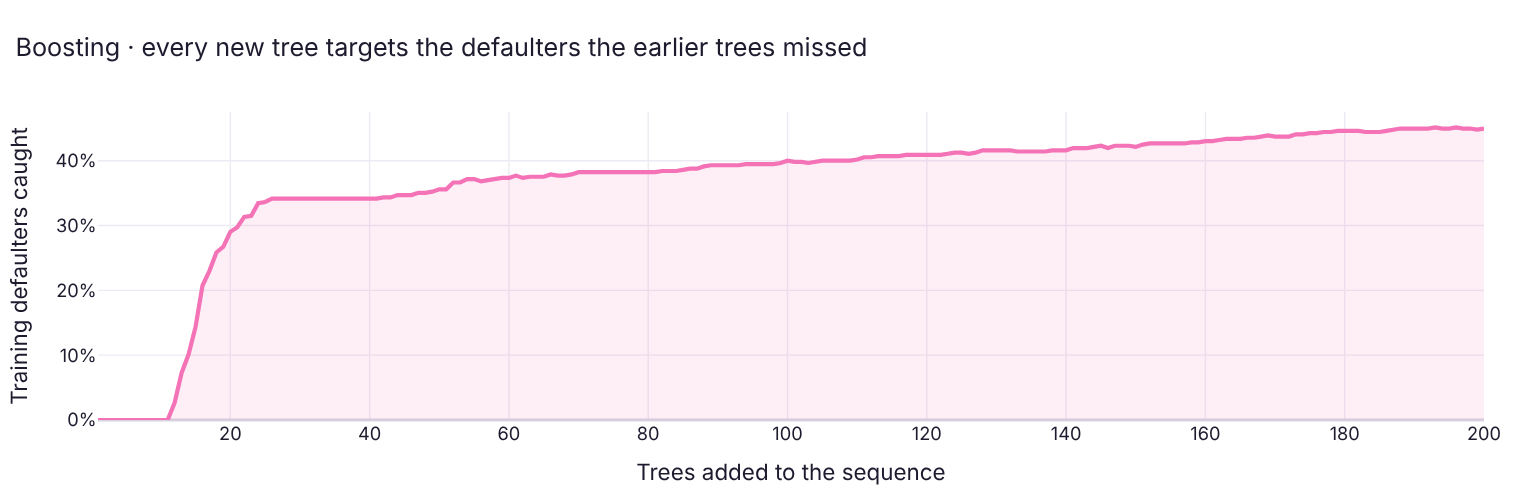

In [13]:
# Boosting in slow motion (training data only, so nothing here peeks at the test set)
gb = fitted["Gradient Boosting"]
stage_recall = [recall_score(y_train, p) for p in gb.staged_predict(X_train)]
fig = go.Figure(go.Scatter(
    x=np.arange(1, len(stage_recall) + 1), y=stage_recall, mode="lines",
    line=dict(color=FAMILY_COLORS["Boosting"], width=3), fill="tozeroy", fillcolor="rgba(244,114,182,0.12)",
    hovertemplate="After %{x} trees: catches %{y:.1%} of training defaulters<extra></extra>"))
fig.update_layout(height=360, title="Boosting · every new tree targets the defaulters the earlier trees missed",
                  xaxis_title="Trees added to the sequence", yaxis_title="Training defaulters caught",
                  yaxis_tickformat=".0%")
fig.show()

**Boosting attacks bias.** With a gentle learning rate, the first 11 trees still approve everyone. After that, tree by tree, the sequence learns to spot defaulters and ends up catching 45 % of training defaulters. **Gradient Boosting (AED 4.77 M)** and **XGBoost (AED 4.58 M)** are the strongest models so far. AdaBoost lags under the 50 % rule; keep an eye on it in Step 4b.

### 3.4 · Stacking: a committee with a manager
Four strong experts from three families each produce a default probability: Random Forest (bagging), Gradient Boosting and XGBoost (boosting), and Logistic Regression (linear). The manager, a logistic regression, is trained on the experts' *out-of-fold* opinions (`cv=5`), so it learns how reliable each expert is on data that expert hasn't seen.

The Random Forest inside the stack is capped at depth 8 because shallower trees give smoother probabilities for the manager to weigh. That choice was made with cross-validation on training data.

In [14]:
stack = StackingClassifier(
    estimators=[
        ("rf",  RandomForestClassifier(n_estimators=200, max_depth=8, random_state=RS, n_jobs=-1)),  # bagging expert
        ("gb",  GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3,
                                           random_state=RS)),                                         # boosting expert
        ("xgb", make_xgb()),                                                                          # boosting expert
        ("lr",  make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),                  # linear expert
    ],
    final_estimator=LogisticRegression(max_iter=1000),   # the manager
    stack_method="predict_proba", cv=5, n_jobs=-1)       # manager learns from 5-fold out-of-fold opinions
add("Stacking", "Stacking", stack)
show_table(board[-1:])

Model,Family,Accuracy,Recall,Money saved (AED),Caught,Good rejected,Missed
Stacking,Stacking,89.5%,32.4%,"4,706,820",61,31,127


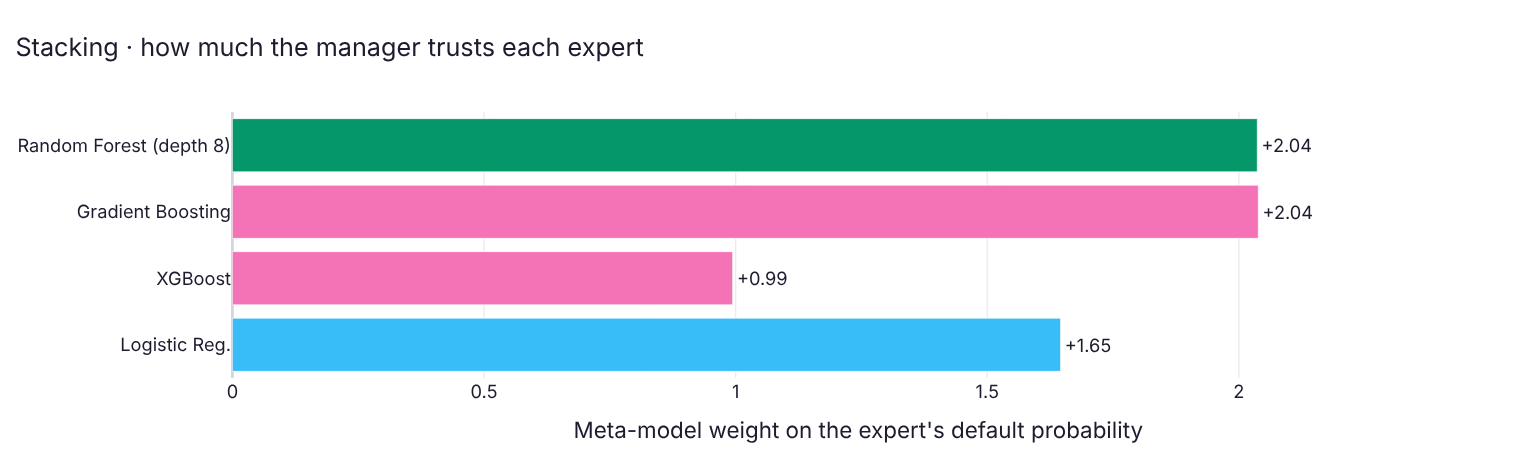

In [15]:
meta = fitted["Stacking"].final_estimator_
experts = ["Random Forest (depth 8)", "Gradient Boosting", XGB_NAME, "Logistic Reg."]
fam_col = [FAMILY_COLORS["Bagging"], FAMILY_COLORS["Boosting"], FAMILY_COLORS["Boosting"], FAMILY_COLORS["Single"]]
w = meta.coef_[0]
fig = go.Figure(go.Bar(x=w, y=experts, orientation="h", marker_color=fam_col,
                       text=[f"{v:+.2f}" for v in w], textposition="outside",
                       hovertemplate="%{y}: weight %{x:+.2f}<extra></extra>"))
fig.update_layout(height=330, title="Stacking · how much the manager trusts each expert",
                  xaxis_title="Meta-model weight on the expert's default probability",
                  xaxis_range=[min(0, w.min() * 1.3), w.max() * 1.22])
fig.update_yaxes(autorange="reversed")
fig.show()

**The manager trusts every expert, but not equally.** Random Forest and Gradient Boosting get the largest weights (about 2.0 each), then Logistic Regression (1.6) and XGBoost (1.0). XGBoost overlaps heavily with Gradient Boosting, so it adds less new information. Every weight is positive, so each expert brings something.

## Step 4 · The Leaderboard 🏆
Every model, the same test set and the same **50 % rule** (`.predict()` rejects only when P(default) > 50 %).

In [16]:
lb = pd.DataFrame(board).sort_values("Money saved (AED)", ascending=False).reset_index(drop=True)
lb.index += 1
champ = lb.iloc[0]

def gold_row(row):
    return ["background-color: #FEF3C7; font-weight: 700" if row["Model"] == champ["Model"] else ""] * len(row)

(lb[["Model", "Family", "Accuracy", "Recall", "Precision", "Money saved (AED)", "Caught", "Good rejected", "Missed"]]
   .style.apply(gold_row, axis=1)
   .bar(subset=["Money saved (AED)"], color="#bbf7d0", vmin=0)
   .format({"Accuracy": "{:.1%}", "Recall": "{:.1%}", "Precision": "{:.1%}", "Money saved (AED)": "{:,.0f}"}))

,Model,Family,Accuracy,Recall,Precision,Money saved (AED),Caught,Good rejected,Missed
1,Gradient Boosting,Boosting,89.6%,33.5%,67.0%,"4,768,240",63,31,125
2,Stacking,Stacking,89.5%,32.4%,66.3%,"4,706,820",61,31,127
3,XGBoost,Boosting,89.3%,31.4%,65.6%,"4,580,800",59,31,129
4,Bagging,Bagging,89.1%,31.4%,62.8%,"4,466,960",59,35,129
5,Random Forest,Bagging,89.4%,30.3%,67.1%,"4,420,000",57,28,131
6,Decision Tree,Single,89.5%,27.7%,70.3%,"3,926,160",52,22,136
7,Logistic Reg.,Single,88.8%,21.8%,66.1%,"3,307,300",41,21,147
8,Voting (soft),Voting,88.9%,20.7%,69.6%,"3,210,960",39,17,149
9,AdaBoost,Boosting,88.9%,18.6%,71.4%,"2,814,220",35,14,153
10,Voting (hard),Voting,88.5%,15.4%,67.4%,"2,395,820",29,14,159


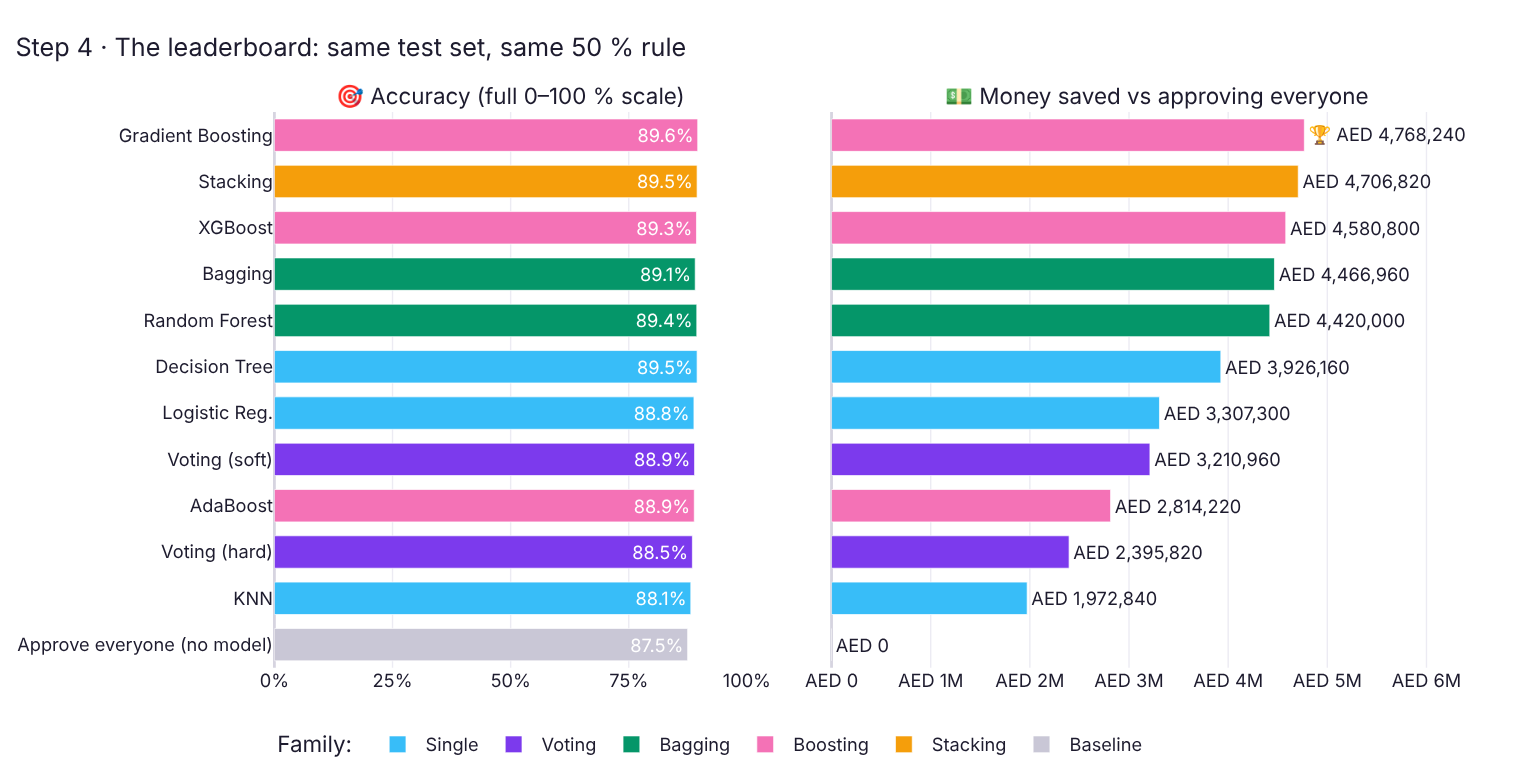

Accuracy, best minus worst : 1.5 percentage points
Money saved, best minus worst: AED 2,795,400  (2.4x)
Champion at the 50 % rule  : Gradient Boosting (Boosting), AED 4,768,240, runner-up Stacking only AED 61,420 behind


In [17]:
plot = pd.concat([lb, pd.DataFrame([{"Model": "Approve everyone (no model)", "Family": "Baseline",
                                    "Accuracy": 1 - y_test.mean(), "Money saved (AED)": 0.0}])], ignore_index=True)
colors = {**FAMILY_COLORS, "Baseline": "#c9c7d6"}
order = plot["Model"].tolist()

fig = make_subplots(rows=1, cols=2, shared_yaxes=True, horizontal_spacing=0.07, column_widths=[0.42, 0.58],
                    subplot_titles=("🎯 Accuracy (full 0–100 % scale)", "💵 Money saved vs approving everyone"))
for fam, col in colors.items():
    sub = plot[plot["Family"] == fam]
    if sub.empty:
        continue
    fig.add_bar(y=sub["Model"], x=sub["Accuracy"], orientation="h", marker_color=col, name=fam,
                legendgroup=fam, text=[f"{a:.1%}" for a in sub["Accuracy"]], textposition="inside",
                insidetextanchor="end", textfont_color="white",
                hovertemplate="%{y}<br>Accuracy %{x:.2%}<extra></extra>", row=1, col=1)
    fig.add_bar(y=sub["Model"], x=sub["Money saved (AED)"], orientation="h", marker_color=col, name=fam,
                legendgroup=fam, showlegend=False,
                text=[("🏆 " if m == champ["Model"] else "") + aed(v) for m, v in zip(sub["Model"], sub["Money saved (AED)"])],
                textposition="outside", cliponaxis=False,
                hovertemplate="%{y}<br>Money saved AED %{x:,.0f}<extra></extra>", row=1, col=2)
fig.update_yaxes(categoryorder="array", categoryarray=order, autorange="reversed")
fig.update_xaxes(range=[0, 1], tickformat=".0%", tickvals=[0, 0.25, 0.5, 0.75, 1], row=1, col=1)
fig.update_xaxes(range=[0, plot["Money saved (AED)"].max() * 1.38], tickprefix="AED ", row=1, col=2)
fig.update_layout(barmode="overlay", height=560, bargap=0.3,
                  title="Step 4 · The leaderboard: same test set, same 50 % rule",
                  legend=dict(orientation="h", y=-0.1, x=0, title_text="Family: "))
fig.show()

acc_spread = lb["Accuracy"].max() - lb["Accuracy"].min()
money_spread = lb["Money saved (AED)"].max() - lb["Money saved (AED)"].min()
print(f"Accuracy, best minus worst : {acc_spread * 100:.1f} percentage points")
print(f"Money saved, best minus worst: {aed(money_spread)}  "
      f"({lb['Money saved (AED)'].max() / lb['Money saved (AED)'].min():.1f}x)")
print(f"Champion at the 50 % rule  : {champ['Model']} ({champ['Family']}), {aed(champ['Money saved (AED)'])}, "
      f"runner-up {lb.iloc[1]['Model']} only {aed(champ['Money saved (AED)'] - lb.iloc[1]['Money saved (AED)'])} behind")

### Reading the leaderboard
- **Accuracy barely moves.** It runs from 88.1 % to 89.6 %, a spread of only **1.5 percentage points**; on a 0–100 % axis the bars look identical. Approving everyone, with no model at all, scores 87.5 %.
- **Money saved swings by AED 2.8 M.** The best model saves **2.4×** as much as the worst (Gradient Boosting AED 4.77 M vs KNN AED 1.97 M).
- **Ensembles take the top five places** (Gradient Boosting, Stacking, XGBoost, Bagging, Random Forest). **Recall** is what separates the field: the top five catch 57–63 defaulters, the single models 23–52.
- **Champion under the brief's rules: Gradient Boosting (AED 4.77 M).** Stacking is AED 61 K behind, a photo finish well within the noise of a test set with 188 defaulters.

**But every model above still misses about two-thirds of the defaulters.** That is partly the models, and partly the **50 % rule**.

## Step 4b · Going further: the 50 % rule is costing money
`.predict()` waits until a model is more than 50 % sure before it rejects. The payoff table says to reject much earlier. Rejecting is worth it when the expected loss is bigger than the expected interest:

$$p \cdot L \;>\; (1-p)\cdot 0.20 \cdot L \quad\Longrightarrow\quad p \;>\; \frac{0.20}{1.20} \;=\; \frac{1}{6} \;\approx\; 16.7\,\%$$

The loan amount $L$ cancels out, so the rule is the same for every applicant: **if the default risk is above 1 in 6, reject.** One lost loan wipes out the interest earned on five good ones.

That's the theory, and it assumes the probabilities are well calibrated. In practice each model finds its own money-maximising cut-off from **5-fold out-of-fold predictions on the training set**. The test set stays untouched until scoring.

In [18]:
# Tune each model's cut-off on TRAINING data only, using 5-fold out-of-fold probabilities.
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)
grid = np.round(np.arange(0.05, 0.605, 0.01), 2)
oof, tuned, oof_curve = {}, {}, {}
t0 = time.time()
for name, model in fitted.items():
    if not hasattr(model, "predict_proba"):          # hard voting gives no probabilities -> nothing to tune
        continue
    oof[name] = cross_val_predict(clone(model), X_train, y_train, cv=skf, method="predict_proba")[:, 1]
    oof_curve[name] = np.array([money_saved(y_train, (oof[name] >= t).astype(int), loan_train) for t in grid])
    tuned[name] = float(grid[oof_curve[name].argmax()])
print(f"Out-of-fold probabilities for {len(oof)} models in {time.time() - t0:.0f}s")
print("Break-even cut-off from the payoff table: 0.20 / 1.20 =", round(0.2 / 1.2, 3))
pd.Series(tuned, name="money-optimal cut-off (training folds)").to_frame().T

Out-of-fold probabilities for 10 models in 53s
Break-even cut-off from the payoff table: 0.20 / 1.20 = 0.167


,Decision Tree,Logistic Reg.,KNN,Voting (soft),Bagging,Random Forest,AdaBoost,Gradient Boosting,XGBoost,Stacking
money-optimal cut-off (training folds),0.2,0.21,0.14,0.17,0.29,0.28,0.4,0.16,0.19,0.14


Most tuned cut-offs land near the theoretical 1/6 (0.14–0.21). The exceptions are telling. **AdaBoost wants 0.40** because its scores huddle around 0.5 and aren't real probabilities, and the bagged trees want about 0.28.

### Leaderboard v2: every model at its own money-tuned cut-off

In [19]:
board2 = [evaluate(n, FAMILY[n], fitted[n], threshold=t) for n, t in tuned.items()]
lb2 = pd.DataFrame(board2).sort_values("Money saved (AED)", ascending=False).reset_index(drop=True)
lb2.index += 1
champ2 = lb2.iloc[0]
before = lb.set_index("Model")["Money saved (AED)"]
lb2["Gain vs 50 % rule"] = lb2["Model"].map(before).rsub(lb2["Money saved (AED)"])

def gold_row2(row):
    return ["background-color: #FEF3C7; font-weight: 700" if row["Model"] == champ2["Model"] else ""] * len(row)

(lb2[["Model", "Family", "Threshold", "Accuracy", "Recall", "Money saved (AED)", "Gain vs 50 % rule",
      "Caught", "Good rejected", "Missed"]]
   .style.apply(gold_row2, axis=1)
   .bar(subset=["Money saved (AED)"], color="#bbf7d0", vmin=0)
   .format({"Threshold": "{:.2f}", "Accuracy": "{:.1%}", "Recall": "{:.1%}",
            "Money saved (AED)": "{:,.0f}", "Gain vs 50 % rule": "{:+,.0f}"}))

,Model,Family,Threshold,Accuracy,Recall,Money saved (AED),Gain vs 50 % rule,Caught,Good rejected,Missed
1,Stacking,Stacking,0.14,86.0%,52.1%,"6,013,540","+1,306,720",98,120,90
2,AdaBoost,Boosting,0.40,85.8%,48.9%,"5,817,520","+3,003,300",92,117,96
3,Voting (soft),Voting,0.17,83.8%,54.3%,"5,802,320","+2,591,360",102,157,86
4,Gradient Boosting,Boosting,0.16,84.0%,53.7%,"5,724,320","+956,080",101,153,87
5,XGBoost,Boosting,0.19,85.5%,50.0%,"5,644,360","+1,063,560",94,123,94
6,Logistic Reg.,Single,0.21,84.7%,51.6%,"5,642,640","+2,335,340",97,139,91
7,Random Forest,Bagging,0.28,87.5%,43.6%,"5,522,640","+1,102,640",82,81,106
8,Decision Tree,Single,0.20,87.2%,41.0%,"5,142,920","+1,216,760",77,81,111
9,Bagging,Bagging,0.29,85.6%,43.1%,"5,045,080","+578,120",81,109,107
10,KNN,Single,0.14,79.7%,52.7%,"4,955,620","+2,982,780",99,216,89


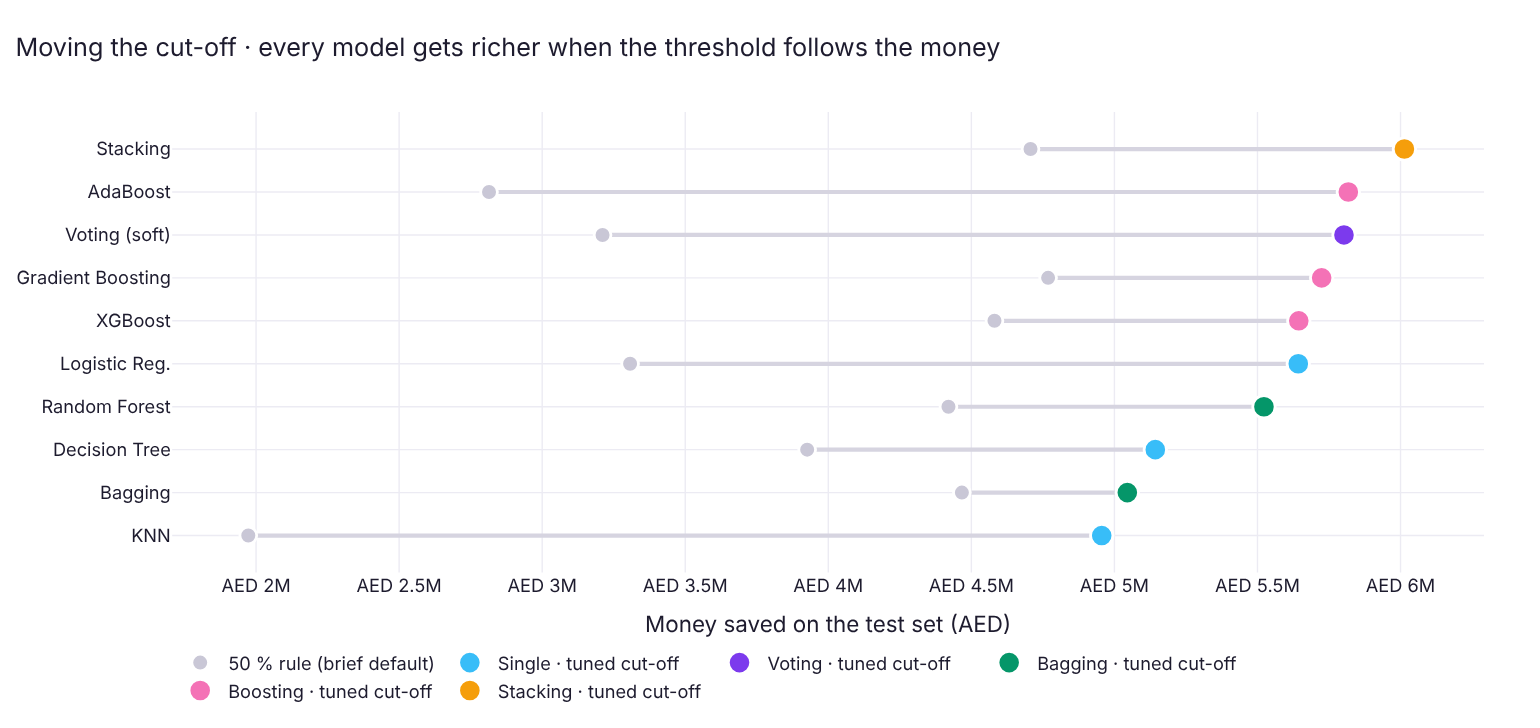

In [20]:
d = lb2.sort_values("Money saved (AED)", ascending=False)
fig = go.Figure()
for _, r in d.iterrows():
    fig.add_trace(go.Scatter(x=[before[r["Model"]], r["Money saved (AED)"]], y=[r["Model"]] * 2, mode="lines",
                             line=dict(color="#d6d4e0", width=3), showlegend=False, hoverinfo="skip"))
fig.add_trace(go.Scatter(x=d["Model"].map(before), y=d["Model"], mode="markers", name="50 % rule (brief default)",
                         marker=dict(size=12, color="#c9c7d6", line=dict(color="white", width=2)),
                         hovertemplate="%{y}<br>50 %% rule: AED %{x:,.0f}<extra></extra>"))
for fam, col in FAMILY_COLORS.items():
    s = d[d["Family"] == fam]
    if len(s):
        fig.add_trace(go.Scatter(x=s["Money saved (AED)"], y=s["Model"], mode="markers", name=f"{fam} · tuned cut-off",
                                 marker=dict(size=16, color=col, line=dict(color="white", width=2)),
                                 customdata=s["Threshold"],
                                 hovertemplate="%{y}<br>cut-off %{customdata:.2f}: AED %{x:,.0f}<extra></extra>"))
fig.update_yaxes(autorange="reversed")
fig.update_layout(height=520, xaxis_title="Money saved on the test set (AED)", xaxis_tickprefix="AED ",
                  title="Moving the cut-off · every model gets richer when the threshold follows the money",
                  legend=dict(orientation="h", y=-0.15, x=0))
fig.show()

**What changed**
- **Every model gains AED 0.6–3.0 M** just by moving its cut-off. The models and training are the same; only the decision rule changed.
- **Stacking becomes the clear champion with AED 6.01 M saved.** It catches **98 of 188** defaulters, so recall rises from 32 % to 52 %.
- **Accuracy *fell*** (89.5 % → 86.0 %) while money rose by AED 1.3 M. We now reject more good borrowers on purpose (120 instead of 31), because each one costs only 20 % of a loan while each extra defaulter caught saves 100 %.
- **AdaBoost jumps from 9th to 2nd.** Once its cut-off is fixed, its ability to rank applicants by risk shows through.

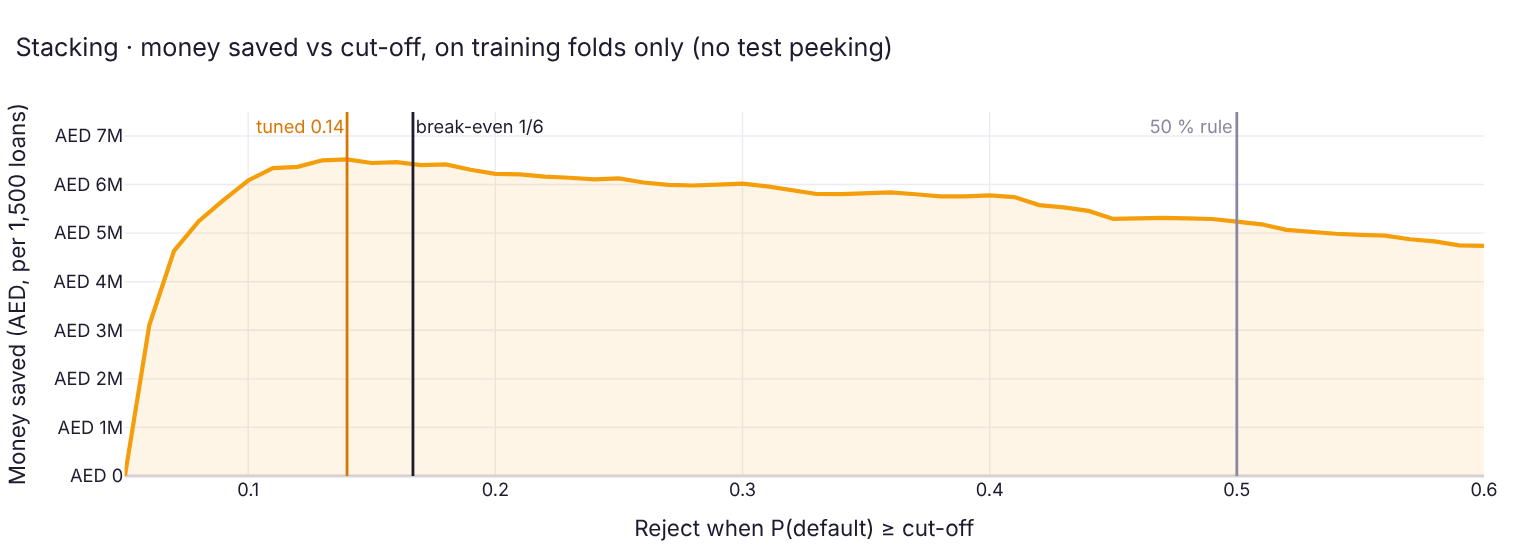

In [21]:
name = champ2["Model"]
fig = go.Figure()
fig.add_trace(go.Scatter(x=grid, y=oof_curve[name] / len(y_train) * len(y_test), mode="lines",
                         line=dict(color=FAMILY_COLORS[FAMILY[name]], width=3), name=name,
                         fill="tozeroy", fillcolor="rgba(245,158,11,0.10)",
                         hovertemplate="cut-off %{x:.2f}: AED %{y:,.0f} per 1,500 loans<extra></extra>"))
for x, label, col, pos in [(0.5, "50 % rule", MUTED, "top left"), (0.2 / 1.2, "break-even 1/6", INK, "top right"),
                           (tuned[name], f"tuned {tuned[name]:.2f}", "#d97706", "top left")]:
    fig.add_vline(x=x, line_color=col, line_width=2, annotation_text=label, annotation_font_color=col,
                  annotation_position=pos)
fig.update_yaxes(range=[0, oof_curve[name].max() / len(y_train) * len(y_test) * 1.15])
fig.update_layout(height=400, showlegend=False, xaxis_title="Reject when P(default) ≥ cut-off",
                  yaxis_title="Money saved (AED, per 1,500 loans)", yaxis_tickprefix="AED ",
                  title=f"{name} · money saved vs cut-off, on training folds only (no test peeking)")
fig.show()

The training-fold curve peaks at **0.14**, right beside the 1/6 break-even line, and stays fairly flat between about 0.11 and 0.20, so the exact cut-off is not a knife-edge choice. By 0.50 the model has given up about AED 1.3 M per 1,500 loans, roughly a fifth of the peak. Push the cut-off much below 0.10, though, and money collapses: the model starts turning away good borrowers en masse.

### Is the champion's win real, or luck?
The test set holds only 188 defaulters, so a single split can flatter a model. Here the contest is re-run **10 times** (5-fold × 2 repeats) on training data for the six strongest contenders, under both cut-off rules. This takes about 1–2 minutes.

In [22]:
# Is the champion's lead real, or luck of one test split? Re-run the contest 10 times on training data.
contenders = ["Logistic Reg.", "Voting (soft)", "Random Forest", "Gradient Boosting", XGB_NAME, "Stacking"]
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=11)
rows, t0 = [], time.time()
for k, (tr, va) in enumerate(rskf.split(X_train, y_train)):
    for name in contenders:
        m = clone(fitted[name]).fit(X_train.iloc[tr], y_train.iloc[tr])
        p = m.predict_proba(X_train.iloc[va])[:, 1]
        yv, lv, scale = y_train.iloc[va], loan_train.iloc[va], 1500 / len(va)
        rows.append({"Model": name, "Fold": k,
                     "50 % rule": money_saved(yv, (p >= 0.5).astype(int), lv) * scale,
                     "Break-even 1/6": money_saved(yv, (p >= 0.2 / 1.2).astype(int), lv) * scale,
                     "Log-loss": log_loss(yv, p)})
cv = pd.DataFrame(rows)
print(f"{len(cv)} fits in {time.time() - t0:.0f}s")
cv_summary = (cv.groupby("Model")[["50 % rule", "Break-even 1/6", "Log-loss"]].mean()
                .reindex(contenders).sort_values("Break-even 1/6", ascending=False))
# Paired view: same folds, head-to-head. In how many of the 10 folds does Stacking beat each rival?
for rule in ["50 % rule", "Break-even 1/6"]:
    piv = cv.pivot(index="Fold", columns="Model", values=rule)
    cv_summary[f"Stacking wins ({rule})"] = ["—" if m == "Stacking" else f"{int((piv['Stacking'] > piv[m]).sum())}/10"
                                            for m in cv_summary.index]
cv_summary.style.format({"50 % rule": "AED {:,.0f}", "Break-even 1/6": "AED {:,.0f}", "Log-loss": "{:.4f}"})

60 fits in 86s


,50 % rule,Break-even 1/6,Log-loss,Stacking wins (50 % rule),Stacking wins (Break-even 1/6)
Model,,,,,
Stacking,"AED 5,363,583","AED 6,434,877",0.2866,—,—
Gradient Boosting,"AED 5,164,833","AED 6,341,313",0.2890,8/10,6/10
Voting (soft),"AED 3,783,973","AED 6,327,493",0.2925,10/10,6/10
XGBoost,"AED 5,185,397","AED 6,243,147",0.2974,6/10,7/10
Random Forest,"AED 5,092,703","AED 5,860,710",0.2973,8/10,9/10
Logistic Reg.,"AED 3,514,763","AED 5,798,810",0.3032,10/10,10/10


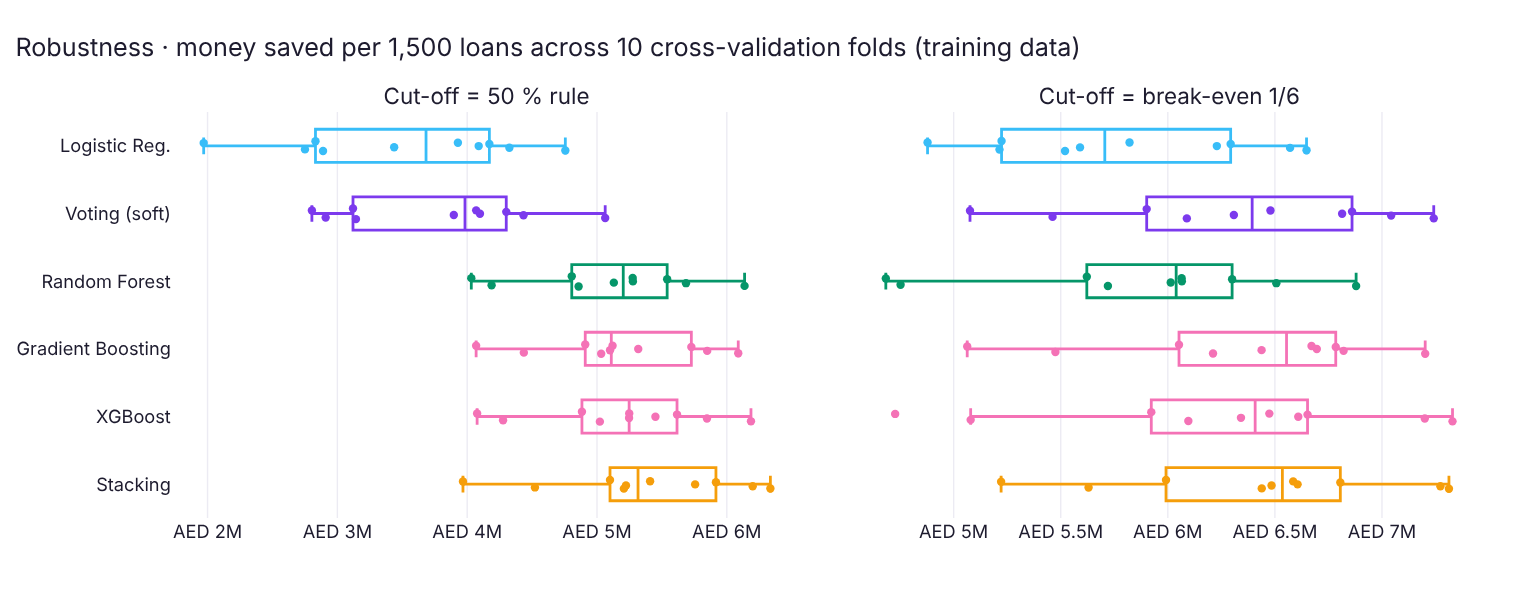

In [23]:
fig = make_subplots(rows=1, cols=2, shared_yaxes=True, horizontal_spacing=0.04,
                    subplot_titles=("Cut-off = 50 % rule", "Cut-off = break-even 1/6"))
for c, col in enumerate(["50 % rule", "Break-even 1/6"], start=1):
    for name in contenders:
        s = cv[cv["Model"] == name]
        fig.add_trace(go.Box(x=s[col], y=[name] * len(s), orientation="h", name=name, boxpoints="all",
                             jitter=0.4, pointpos=0, marker=dict(size=6, color=FAMILY_COLORS[FAMILY[name]]),
                             line=dict(color=FAMILY_COLORS[FAMILY[name]], width=2),
                             fillcolor="rgba(255,255,255,0)", showlegend=False,
                             hovertemplate=name + "<br>AED %{x:,.0f}<extra></extra>"), row=1, col=c)
fig.update_yaxes(categoryorder="array", categoryarray=contenders[::-1])
fig.update_xaxes(tickprefix="AED ")
fig.update_layout(height=430, title="Robustness · money saved per 1,500 loans across 10 cross-validation folds (training data)")
fig.show()

- **Stacking has the highest average money under both rules** (AED 5.36 M with the 50 % rule, AED 6.43 M with the 1/6 rule) and the **lowest log-loss**, meaning the most trustworthy probabilities.
- Head-to-head on the same folds, Stacking beats Logistic Regression in **10/10** folds and Random Forest in 9/10. **Gradient Boosting is the closest rival** (Stacking wins 6/10 at the 1/6 rule, by AED 94 K on average).
- Single folds swing by ±AED 0.65 M, so a one-split gap like Gradient Boosting vs Stacking under the 50 % rule (AED 61 K) is noise. The 10-fold picture is the more reliable signal.

## What drives the decision? (interpretability check)
Stacking is a black box, so it has to be tested from the outside. The check below scrambles one column at a time and measures how much money the champion loses.

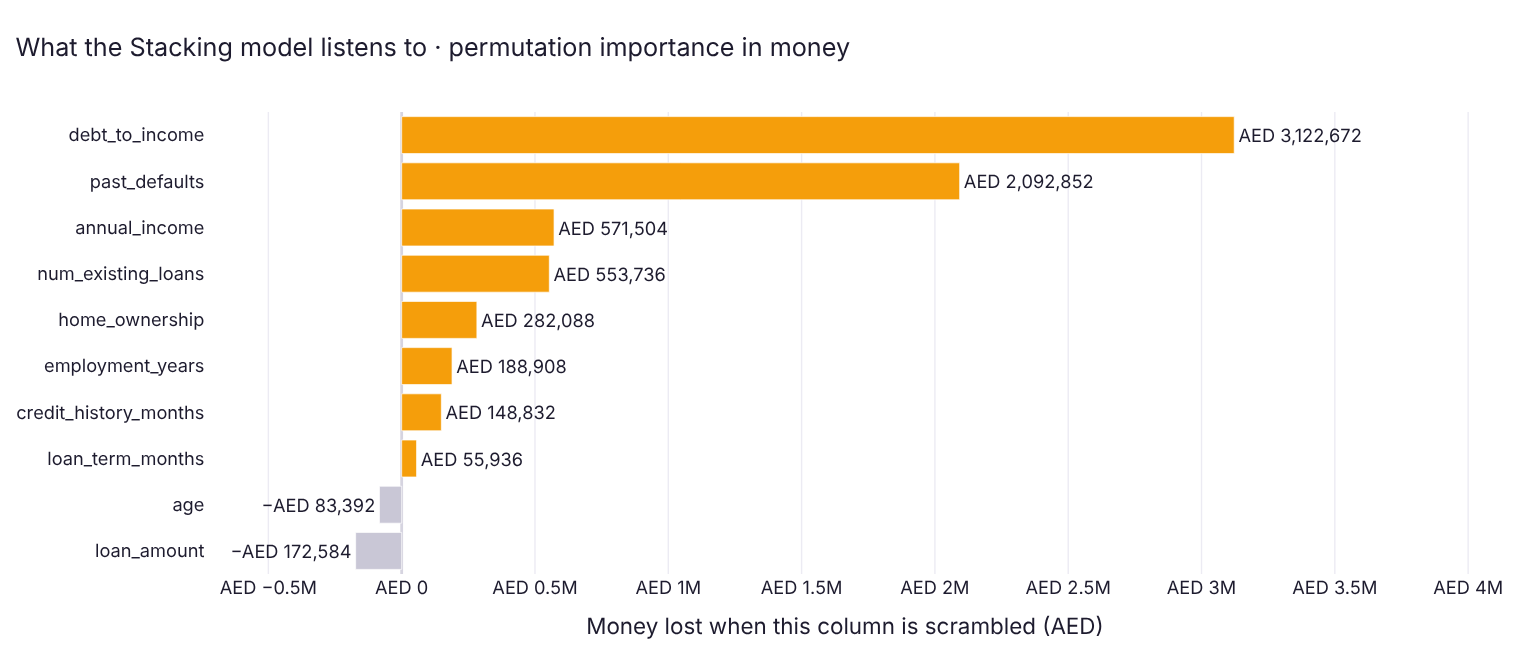

In [24]:
# Which applicant facts drive the champion's money? Shuffle one column at a time and see how much money is lost.
champ_model, champ_t = fitted[champ2["Model"]], tuned[champ2["Model"]]

def money_at(Xs):
    return money_saved(y_test, (champ_model.predict_proba(Xs)[:, 1] >= champ_t).astype(int), loan_test)

base = money_at(X_test)
groups = {c: [c] for c in df.columns if c not in ("default", "home_ownership")}
groups["home_ownership"] = [c for c in X_test.columns if c.startswith("home_ownership_")]
rng = np.random.default_rng(RS)
imp = {}
for feat, cols in groups.items():
    drops = []
    for _ in range(5):
        Xp = X_test.copy()
        Xp[cols] = Xp[cols].values[rng.permutation(len(Xp))]
        drops.append(base - money_at(Xp))
    imp[feat] = np.mean(drops)
imp = pd.Series(imp).sort_values()

fig = go.Figure(go.Bar(x=imp.values, y=imp.index, orientation="h",
                       marker_color=[FAMILY_COLORS["Stacking"] if v > 0 else "#c9c7d6" for v in imp.values],
                       text=[aed(v) for v in imp.values], textposition="outside", cliponaxis=False,
                       hovertemplate="Shuffle %{y}: lose AED %{x:,.0f}<extra></extra>"))
fig.update_layout(height=470, xaxis_title="Money lost when this column is scrambled (AED)", xaxis_tickprefix="AED ",
                  xaxis_range=[min(0, imp.min()) - 0.18 * imp.max(), imp.max() * 1.3],
                  title=f"What the {champ2['Model']} model listens to · permutation importance in money")
fig.show()

- **Debt-to-income (AED 3.1 M)** and **past defaults (AED 2.1 M)** carry most of the value. These are the same two signals the exploration flagged. Income and the number of existing loans add about AED 0.55 M each.
- **Loan amount and age come out slightly negative**, so scrambling them doesn't hurt. The model already sees loan size through debt-to-income. Both are candidates to drop in a future version.
- These drivers are sensible and easy to explain, so QuickLoan can tell an applicant *why* in plain language even though the model itself is complex.

## Step 5 · The verdict 📝

> **To:** QuickLoan leadership  **From:** Risk team  **Re:** Which default model to deploy

**Recommendation: deploy the Stacking ensemble** (Random Forest + Gradient Boosting + XGBoost + Logistic Regression, combined by a logistic-regression "manager"), and **reject any applicant whose predicted default risk is 14 % or higher.**

**What it's worth.** On 1,500 held-out applications it saves **AED 6.01 M compared with approving everyone**. That is about **AED 4,000 per application**, and **49 %** of the AED 12.27 M a perfect crystal ball could save.

| Same 1,500 test loans | Money saved | Defaulters caught | Accuracy |
|---|---|---|---|
| Approve everyone (naive policy) | AED 0 | 0 of 188 | 87.5 % |
| Best single model, 50 % rule (Decision Tree) | AED 3.93 M | 52 (27.7 %) | 89.5 % |
| Brief's champion, 50 % rule (Gradient Boosting) | AED 4.77 M | 63 (33.5 %) | 89.6 % |
| **Stacking, 14 % cut-off (recommended)** | **AED 6.01 M** | **98 (52.1 %)** | **86.0 %** |

**Why this model**
1. It saves the **most money on the test set**, and it also saves the **most on average across 10 cross-validation folds** under both cut-off rules. It is the most consistent winner, not a lucky one.
2. It gives the **best-calibrated probabilities** (lowest log-loss). That matters because our decision rule *is* a probability cut-off.
3. The cut-off comes from the payoff table (break-even ≈ 1/6) and was confirmed on training data only.

**Trade-offs we accept**
- **Lower accuracy (89.5 % → 86.0 %), on purpose.** We turn away **120** good borrowers, each costing about 20 % of a loan in lost interest, in order to stop **98** defaulters, each saving 100 % of a loan. Accuracy counts those two mistakes as equal; our P&L does not.
- **Less interpretability.** Stacking is harder to explain than a scorecard. To compensate: permutation importance shows clear, sensible drivers (debt-to-income, past defaults, income); we keep the logistic-regression scorecard as a challenger model and as the source of reason codes for rejected applicants; and if leadership prefers a single, simpler model, **Gradient Boosting at a 16 % cut-off** is the closest runner-up (about AED 0.1–0.3 M less).
- **More complexity.** It takes about 7 seconds to train and milliseconds to score each applicant, which is not a constraint at QuickLoan's scale.

**Conditions for go-live**
- Re-tune the cut-off whenever the interest rate changes (break-even = interest ÷ (1 + interest)). The dashboard shows this live.
- Monitor monthly: defaulters caught, good customers rejected, and money saved vs approve-all.
- The data is one 6,000-row snapshot. Validate on fresh applications before full roll-out, and compare outcomes across home-ownership groups for fairness.

## Saving the champion for the dashboard
`app.py` loads `loan_model.joblib`. We save the model, its column order **and its cut-off**. The upgraded `app.py` reads the cut-off; the original one would fall back to the 50 % rule.

In [25]:
DEPLOY = champ2["Model"]
joblib.dump({"model": fitted[DEPLOY], "columns": list(X_train.columns),
             "threshold": tuned[DEPLOY], "name": DEPLOY, "interest": 0.20}, "loan_model.joblib")

# Sanity check: reload and reproduce the dashboard's money card exactly
M = joblib.load("loan_model.joblib")
p = M["model"].predict_proba(X_test[M["columns"]])[:, 1]
pred = (p >= M["threshold"]).astype(int)
print(f"Saved loan_model.joblib -> {M['name']} with cut-off {M['threshold']:.2f}")
print(f"Money saved vs approve-all : {aed(money_saved(y_test, pred, loan_test))}")
print(f"Defaulters caught          : {int(((pred == 1) & (y_test.values == 1)).sum())}/{int(y_test.sum())}")
print(f"Good borrowers rejected    : {int(((pred == 1) & (y_test.values == 0)).sum())}")

Saved loan_model.joblib -> Stacking with cut-off 0.14
Money saved vs approve-all : AED 6,013,540
Defaulters caught          : 98/188
Good borrowers rejected    : 120


**Run the dashboard:** keep `app.py`, `loan_model.joblib` and `loans.csv` in one folder, then run `streamlit run app.py`. The interactive HTML leaderboard (`QuickLoan_Dashboard.html`) opens in any browser with no setup.